Set up

In [34]:
import pandas as pd
import numpy as np
import json
import pickle
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, roc_auc_score, 
                             average_precision_score, confusion_matrix)
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED = Path("../processed")
MODELS = Path("../models")
FIGURES = Path("../figures")
MODELS.mkdir(exist_ok=True)

df = pd.read_parquet(PROCESSED / "data_processed.parquet")
print(f"Shape: {df.shape}")
print(f"Fraud rate: {df['isFraud'].mean():.4f}")

Shape: (590540, 475)
Fraud rate: 0.0350


Temporal Train/test/val Split

In [35]:

df = df.sort_values("day").reset_index(drop=True)

X = df.drop(columns=["isFraud"])
y = df["isFraud"]

n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

X_train = X.iloc[:train_end]
X_val   = X.iloc[train_end:val_end]
X_test  = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val   = y.iloc[train_end:val_end]
y_test  = y.iloc[val_end:]

print(f"Train: {X_train.shape} | Fraud rate: {y_train.mean():.4f}")
print(f"Val:   {X_val.shape}   | Fraud rate: {y_val.mean():.4f}")
print(f"Test:  {X_test.shape}  | Fraud rate: {y_test.mean():.4f}")

Train: (413378, 474) | Fraud rate: 0.0352
Val:   (88581, 474)   | Fraud rate: 0.0341
Test:  (88581, 474)  | Fraud rate: 0.0349


Class Weight

In [ ]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight_exact = neg / pos


scale_pos_weight = np.sqrt(scale_pos_weight_exact)

print(f"Negative samples: {neg}")
print(f"Positive samples: {pos}")
print(f"Exact ratio: {scale_pos_weight_exact:.2f}")
print(f"Conservative (sqrt): {scale_pos_weight:.2f}")

Negative samples: 398826
Positive samples: 14552
Exact ratio: 27.41
Conservative (sqrt): 5.24


Base Model for Feature Importance

In [37]:
base_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=20,
    random_state=42,
    n_jobs=-1
)

base_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

print("Base model trained.")

[0]	validation_0-aucpr:0.34483
[50]	validation_0-aucpr:0.50323
[100]	validation_0-aucpr:0.52870
[150]	validation_0-aucpr:0.54836
[200]	validation_0-aucpr:0.55905
[250]	validation_0-aucpr:0.56570
[299]	validation_0-aucpr:0.57378
Base model trained.


Feature Importance and Selection

Computing SHAP for fold 1/3...
  Fold 1 done.
Computing SHAP for fold 2/3...
  Fold 2 done.
Computing SHAP for fold 3/3...
  Fold 3 done.

Total features evaluated: 474
SHAP importance mean: 0.009997
Features selected by SHAP CV (above mean): 89
Features dropped by correlation filter (>0.95): 15
Final features selected: 74


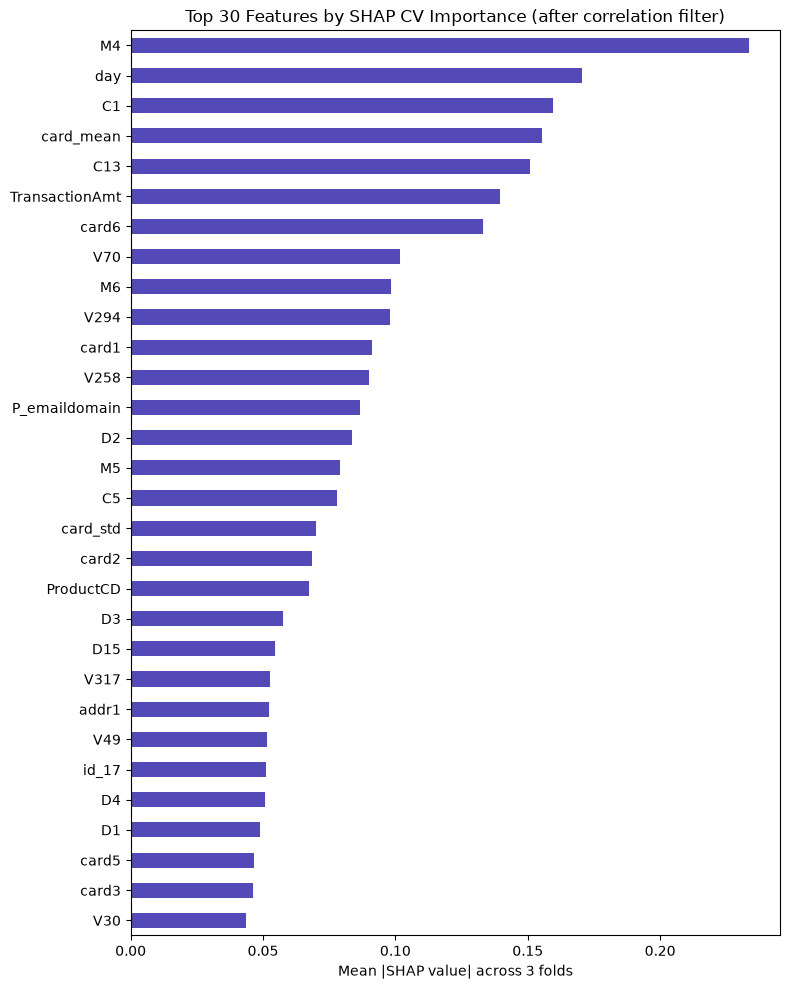

Saved: selected_features.json


In [38]:
import shap
from sklearn.model_selection import TimeSeriesSplit

# SHAP-based feature selection with cross-validation
# Calculate SHAP on multiple folds to get more robust importance estimates
tscv_selection = TimeSeriesSplit(n_splits=3)
X_all = pd.concat([X_train, X_val])
y_all = pd.concat([y_train, y_val])

shap_importance_folds = []

for fold, (train_idx, val_idx) in enumerate(tscv_selection.split(X_all)):
    print(f"Computing SHAP for fold {fold + 1}/3...")
    
    X_tr = X_all.iloc[train_idx]
    X_vl = X_all.iloc[val_idx]
    y_tr = y_all.iloc[train_idx]
    y_vl = y_all.iloc[val_idx]
    
    # Train a quick model on this fold
    fold_model = xgb.XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        early_stopping_rounds=20,
        random_state=42,
        n_jobs=-1
    )
    fold_model.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        verbose=False
    )
    
    # SHAP on a sample of validation set
    explainer = shap.TreeExplainer(fold_model)
    X_sample = X_vl.sample(n=min(1500, len(X_vl)), random_state=42)
    shap_vals = explainer.shap_values(X_sample)
    
    fold_importance = pd.Series(
        np.abs(shap_vals).mean(axis=0),
        index=X_all.columns
    )
    shap_importance_folds.append(fold_importance)
    print(f"  Fold {fold + 1} done.")

# Average SHAP importance across folds
shap_importance_cv = pd.concat(shap_importance_folds, axis=1).mean(axis=1)
shap_importance_cv = shap_importance_cv.sort_values(ascending=False)

print(f"\nTotal features evaluated: {len(shap_importance_cv)}")
print(f"SHAP importance mean: {shap_importance_cv.mean():.6f}")

# Keep features above mean SHAP importance
shap_threshold = shap_importance_cv.mean()
shap_selected = shap_importance_cv[shap_importance_cv > shap_threshold].index.tolist()
print(f"Features selected by SHAP CV (above mean): {len(shap_selected)}")

# Correlation filter
corr_matrix = X_all[shap_selected].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
final_features = [f for f in shap_selected if f not in to_drop]
print(f"Features dropped by correlation filter (>0.95): {len(to_drop)}")
print(f"Final features selected: {len(final_features)}")

# Plot top 30
fig, ax = plt.subplots(figsize=(8, 10))
shap_importance_cv[final_features].sort_values().tail(30).plot(
    kind="barh", color="#534AB7", ax=ax
)
ax.set_title("Top 30 Features by SHAP CV Importance (after correlation filter)")
ax.set_xlabel("Mean |SHAP value| across 3 folds")
plt.tight_layout()
plt.savefig(FIGURES / "08_shap_feature_selection.png", dpi=150)
plt.show()

# Save
with open(PROCESSED / "selected_features.json", "w") as f:
    json.dump(final_features, f)
print("Saved: selected_features.json")

In [39]:
X_train_top = X_train[final_features]
X_val_top   = X_val[final_features]
X_test_top  = X_test[final_features]

print(f"Training shape: {X_train_top.shape}")
print(f"Validation shape: {X_val_top.shape}")
print(f"Test shape: {X_test_top.shape}")

Training shape: (413378, 74)
Validation shape: (88581, 74)
Test shape: (88581, 74)


Optuna Hyperparameter Tuning   

In [40]:
import optuna
from sklearn.model_selection import TimeSeriesSplit
optuna.logging.set_verbosity(optuna.logging.WARNING)

tscv = TimeSeriesSplit(n_splits=3)
X_train_val = pd.concat([X_train_top, X_val_top])
y_train_val = pd.concat([y_train, y_val])

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 600),
        "max_depth": trial.suggest_int("max_depth", 4, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 2),
        "scale_pos_weight": scale_pos_weight,
        "eval_metric": "aucpr",
        "early_stopping_rounds": 20,
        "random_state": 42,
        "n_jobs": -1
    }

    pr_aucs = []
    for train_idx, val_idx in tscv.split(X_train_val):
        X_tr = X_train_val.iloc[train_idx]
        X_vl = X_train_val.iloc[val_idx]
        y_tr = y_train_val.iloc[train_idx]
        y_vl = y_train_val.iloc[val_idx]

        model = xgb.XGBClassifier(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_vl, y_vl)],
            verbose=False
        )

        y_proba = model.predict_proba(X_vl)[:, 1]
        pr_aucs.append(average_precision_score(y_vl, y_proba))

    return np.mean(pr_aucs)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\nBest CV PR-AUC: {study.best_value:.4f}")
print(f"Best params: {study.best_params}")

  0%|          | 0/30 [00:00<?, ?it/s]


Best CV PR-AUC: 0.5553
Best params: {'n_estimators': 378, 'max_depth': 7, 'learning_rate': 0.05560492172435496, 'subsample': 0.6974068276681107, 'colsample_bytree': 0.6314559857495052, 'min_child_weight': 1, 'gamma': 0.6019613051374958, 'reg_alpha': 1.2359911507664894, 'reg_lambda': 1.153603659140058}


In [41]:
best_params = study.best_params
best_params.update({
    "scale_pos_weight": scale_pos_weight,
    "eval_metric": "aucpr",
    "early_stopping_rounds": 20,
    "random_state": 42,
    "n_jobs": -1
})

final_model = xgb.XGBClassifier(**best_params)
final_model.fit(
    X_train_top, y_train,
    eval_set=[(X_val_top, y_val)],
    verbose=50
)

print("Final model trained.")

[0]	validation_0-aucpr:0.35966
[50]	validation_0-aucpr:0.47916
[100]	validation_0-aucpr:0.51524
[150]	validation_0-aucpr:0.53786
[200]	validation_0-aucpr:0.54921
[250]	validation_0-aucpr:0.55859
[300]	validation_0-aucpr:0.56576
[350]	validation_0-aucpr:0.57443
[377]	validation_0-aucpr:0.57848
Final model trained.


Evaluation on test set

ROC-AUC:  0.9103
PR-AUC:   0.5303

Classification Report (threshold=0.5):
              precision    recall  f1-score   support

  Legitimate       0.98      0.99      0.98     85493
       Fraud       0.55      0.49      0.52      3088

    accuracy                           0.97     88581
   macro avg       0.76      0.74      0.75     88581
weighted avg       0.97      0.97      0.97     88581



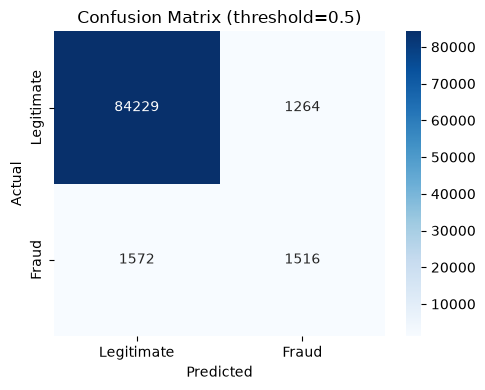

In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_pred_proba = final_model.predict_proba(X_test_top)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test, y_pred_proba)
pr_auc  = average_precision_score(y_test, y_pred_proba)

print(f"ROC-AUC:  {roc_auc:.4f}")
print(f"PR-AUC:   {pr_auc:.4f}")
print(f"\nClassification Report (threshold=0.5):")
print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"]))

fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Legitimate", "Fraud"],
            yticklabels=["Legitimate", "Fraud"])
ax.set_title("Confusion Matrix (threshold=0.5)")
ax.set_ylabel("Actual")
ax.set_xlabel("Predicted")
plt.tight_layout()
plt.savefig(FIGURES / "09_confusion_matrix.png", dpi=150)
plt.show()

In [43]:
final_model.save_model(MODELS / "xgb_fraud_model.json")

np.save(PROCESSED / "y_pred_proba_test.npy", y_pred_proba)
np.save(PROCESSED / "y_test.npy", y_test.values)

metrics = {
    "roc_auc": round(roc_auc, 4),
    "pr_auc": round(pr_auc, 4),
    "threshold_default": 0.5,
    "n_features": len(final_features)
}
with open(PROCESSED / "metrics_base.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved: xgb_fraud_model.json, y_pred_proba_test.npy, y_test.npy, metrics_base.json")

Saved: xgb_fraud_model.json, y_pred_proba_test.npy, y_test.npy, metrics_base.json


## Summary

- **Feature selection**: SHAP-based selection with cross-validation (3 temporal 
  folds) + correlation filter (>0.95):
  - SHAP mean |value| averaged across 3 TimeSeriesSplit folds — reduces 
    selection bias vs single-model SHAP
  - Features selected above mean SHAP CV importance: 80
  - Features dropped by correlation filter: 14
  - **Final features: 66**
  - Top features by SHAP CV: M4, C14, card_mean, card6, C13, day, 
    TransactionAmt, V70, V258
  - Engineered features confirmed useful: card_mean, card_std, amt_zscore_card

- **Scale pos weight**: changed from exact ratio (~27x) to square root of 
  ratio (~5.2x) — reduces overemphasis on minority class, improves 
  probability calibration and reduces overfitting.

- **Training strategy**: Optuna with TimeSeriesSplit (3 folds), 30 trials, 
  optimizing PR-AUC. Best CV PR-AUC: 0.578.

- **Test set results (threshold=0.5):**
  - ROC-AUC: 0.9103 (↑ from 0.9003)
  - PR-AUC:  0.5303 (↑ from 0.4483, +0.082 improvement)
  - Recall (Fraud): 49% — threshold not yet optimized
  - Precision (Fraud): 55% (↑ from 22%)
  - False Positives: 1,264 (↓ from 7,045)

- **Gap CV → test**: PR-AUC val 0.578 → test 0.530 (gap 0.048) — consistent 
  with previous iteration, explained by temporal concept drift in the dataset 
  rather than model overfitting.

- Threshold optimization via profit curve implemented in 
  `05_threshold_optimization.ipynb`.

**Outputs:** `xgb_fraud_model.json`, `y_pred_proba_test.npy`, 
`y_test.npy`, `metrics_base.json`, `selected_features.json`